# Laboratorium 5 - rekomendacje grupowe

## Przygotowanie

 * pobierz i wypakuj dataset: https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
   * więcej możesz poczytać tutaj: https://grouplens.org/datasets/movielens/
 * `pip install numpy pandas scipy matplotlib`

Testy jednostkowe w notatniku korzystają z przykładu z wykładu (Alice, Bob, Carol; filmy A-F).

## Część 1. - dane

In [1]:
import unittest
from abc import ABC, abstractmethod
from dataclasses import dataclass
from itertools import cycle
from typing import Dict, Hashable, List, Sequence, Type

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse.linalg import svds

Item = Hashable  # id filmu (w danych) lub nazwa ('A', 'B', ...) w przykladzie z wykladu
Group = List[int]  # lista id uzytkownikow

In [2]:
@dataclass(frozen=True)
class Params:
    data_path: str = 'data/ml-latest-small'
    min_movie_ratings: int = 30  # bierzemy tylko filmy z co najmniej tyloma ocenami
    svd_rank: int = 20  # liczba czynnikow ukrytych w dekompozycji
    scale: int = 10  # oceny po normalizacji: 1, 2, ..., scale
    group_size: int = 5
    groups_per_type: int = 50
    recommendation_size: int = 10
    approval_threshold: int = 8  # ocena >= progu = film akceptowany (glosowanie, PAV)
    misery_threshold: int = 4  # ocena < progu = niezadowolenie (srednia bez niezadowolenia)
    seed: int = 42


PARAMS = Params()

Algorytmy grupowe potrzebują oceny **każdego** filmu przez **każdego** członka grupy.
Brakujące oceny przewidujemy dekompozycją macierzy (SVD o niskim rzędzie).

In [3]:
def load_ratings(params: Params) -> pd.DataFrame:
    reviews = pd.read_csv(f'{params.data_path}/ratings.csv', usecols=['userId', 'movieId', 'rating'])
    counts = reviews.movieId.value_counts()
    reviews = reviews[reviews.movieId.isin(counts[counts >= params.min_movie_ratings].index)]
    return reviews.pivot(index='userId', columns='movieId', values='rating')


# idea: https://www.kaggle.com/code/indralin/movielens-project-1-2-collaborative-filtering
# niski rzad wymusza uogolnienie - przy rzedzie bliskim liczbie uzytkownikow SVD odtwarza macierz
# niemal dokladnie, a brakujace oceny to po prostu srednia uzytkownika (wszystkie filmy rownie dobre)

def predict_ratings(observed: pd.DataFrame, rank: int) -> pd.DataFrame:
    user_means = np.nanmean(observed.values, axis=1, keepdims=True)
    centered = np.nan_to_num(observed.values - user_means)
    u, sigma, vt = svds(centered, k=rank)
    predicted = u @ np.diag(sigma) @ vt + user_means
    return pd.DataFrame(predicted, index=observed.index, columns=observed.columns)


observed = load_ratings(PARAMS)
predicted = predict_ratings(observed, PARAMS.svd_rank)
print(f'{observed.notna().sum().sum()} ocen, {observed.shape[0]} uzytkownikow, {observed.shape[1]} filmow')
print(f'wypelnienie macierzy: {observed.notna().mean().mean():.1%}')

58018 ocen, 609 uzytkownikow, 882 filmow
wypelnienie macierzy: 10.8%


**Problem:** MovieLens ma nadreprezentację wysokich ocen (średnia ~3.5 na 5), a przewidywania są jeszcze bardziej
ściśnięte wokół średniej użytkownika. Prawie każdy film jest „całkiem dobry” dla każdego, więc nawet losowa
rekomendacja wypada nieźle i różnice między algorytmami się zacierają.

**Normalizacja:** przewidywane oceny każdego użytkownika zamieniamy na **decyle** - 10% filmów najwyżej
ocenianych przez użytkownika dostaje 10, kolejne 10% - 9, ..., najsłabsze 10% - 1.
 * każdy użytkownik wykorzystuje całą skalę, a ocena 5 oznacza dla wszystkich to samo (połowa filmów jest lepsza)
 * tracimy informację, że ktoś „lubi wszystko” - ale porównywalność ocen między osobami jest ważniejsza,
   bo algorytmy grupowe porównują i sumują oceny różnych ludzi

In [4]:
def to_deciles(predicted: pd.DataFrame, scale: int) -> pd.DataFrame:
    percentiles = predicted.rank(axis=1, method='first', pct=True)  # (0, 1], bez remisow
    return np.ceil(percentiles * scale).astype(int)


ratings = to_deciles(predicted, PARAMS.scale)
# dostep do danych:
# ratings.loc[user_id, movie_id] - jedna ocena
# ratings.loc[group] - oceny czlonkow grupy (wiersze) dla wszystkich filmow (kolumny)
ratings

movieId,1,2,3,5,6,7,10,11,16,17,...,115617,116797,119145,122882,122886,122904,134130,134853,139385,152081
userId,,,,,,,,,,,,,,,,,,,,,
1,3,3,2,2,1,1,1,6,4,2,...,4,7,5,4,5,5,7,5,6,4
2,3,2,1,8,8,7,10,4,6,3,...,3,6,8,10,10,8,7,5,5,6
3,4,9,9,6,9,10,5,6,4,1,...,6,5,9,9,7,8,6,8,7,7
4,9,2,3,4,2,1,8,5,5,5,...,8,7,4,2,6,7,5,4,3,4
5,10,8,7,5,10,9,1,10,10,9,...,7,6,3,1,2,2,3,5,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,6,1,3,2,7,2,6,1,7,9,...,4,8,6,7,4,3,6,5,6,3
607,3,7,10,6,9,2,3,8,7,4,...,5,8,5,4,4,3,5,4,6,8
608,1,1,1,3,7,3,10,3,10,9,...,4,4,4,4,6,3,7,5,5,6


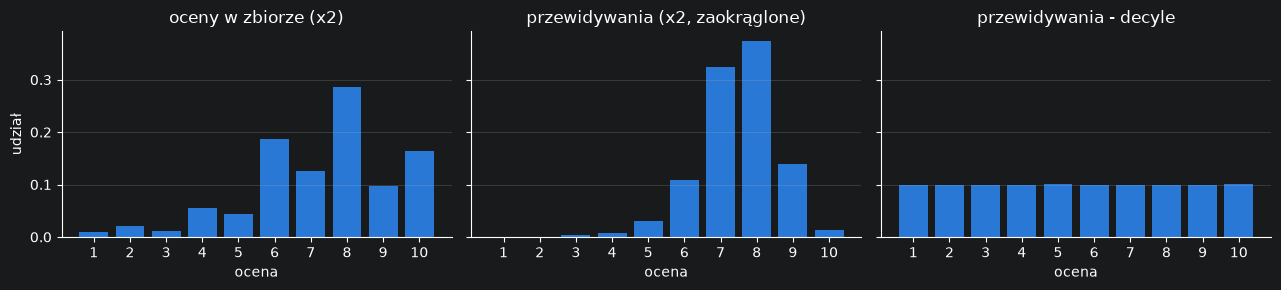

In [5]:
def value_shares(values: np.ndarray, scale: int) -> np.ndarray:
    values = np.asarray(values, dtype=float).ravel()
    values = values[np.isfinite(values)]
    if values.size == 0:
        return np.zeros(scale, dtype=float)
    return np.bincount(values.astype(int), minlength=scale + 1)[1:] / values.size


distributions = {
    'oceny w zbiorze (x2)': value_shares(2 * observed.stack().values, PARAMS.scale),
    'przewidywania (x2, zaokrąglone)': value_shares(np.rint(2 * predicted.values.clip(0.5, 5)).ravel(), PARAMS.scale),
    'przewidywania - decyle': value_shares(ratings.values.ravel(), PARAMS.scale),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, (title, shares) in zip(axes, distributions.items()):
    ax.bar(range(1, PARAMS.scale + 1), shares, color='#2a78d6')
    ax.set_title(title)
    ax.set_xticks(range(1, PARAMS.scale + 1))
    ax.set_xlabel('ocena')
    ax.grid(axis='y', alpha=0.3)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel('udział')
plt.tight_layout()
plt.show()

In [6]:
# nazwy filmow i kategorie
movies = pd.read_csv(f'{PARAMS.data_path}/movies.csv').set_index('movieId')
movies

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,Jumanji (1995),Adventure|Children|Fantasy
3,Grumpier Old Men (1995),Comedy|Romance
4,Waiting to Exhale (1995),Comedy|Drama|Romance
5,Father of the Bride Part II (1995),Comedy
...,...,...
193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
193585,Flint (2017),Drama


### Grupy

Zamiast stałej listy grup losujemy trzy rodzaje grup (powtarzalnie - ustalony `seed`):
 * **losowe** - przypadkowi użytkownicy
 * **podobne** - zaczynamy od losowej osoby i zachłannie dobieramy kolejną najbardziej skorelowaną z dotychczasowymi członkami
 * **rozbieżne** - jak wyżej, ale dobieramy osobę najmniej skorelowaną

In [7]:
def grow_group(similarity: np.ndarray, first: int, size: int, most_similar: bool) -> List[int]:
    members = [first]
    while len(members) < size:
        mean_similarity = similarity[members].mean(axis=0)
        mean_similarity[members] = np.nan  # pomijamy obecnych czlonkow
        members.append(int(np.nanargmax(mean_similarity) if most_similar else np.nanargmin(mean_similarity)))
    return members


def make_groups(ratings: pd.DataFrame, params: Params) -> Dict[str, List[Group]]:
    rng = np.random.default_rng(params.seed)
    users = ratings.index.to_numpy()
    similarity = np.corrcoef(ratings.values)  # korelacja Pearsona ocen kazdej pary uzytkownikow
    seeds = rng.choice(len(users), params.groups_per_type, replace=False)
    positions = {
        'losowe': [rng.choice(len(users), params.group_size, replace=False) for _ in range(params.groups_per_type)],
        'podobne': [grow_group(similarity, s, params.group_size, most_similar=True) for s in seeds],
        'rozbieżne': [grow_group(similarity, s, params.group_size, most_similar=False) for s in seeds],
    }
    return {kind: [users[group].tolist() for group in groups] for kind, groups in positions.items()}


groups = make_groups(ratings, PARAMS)
{kind: kind_groups[:3] for kind, kind_groups in groups.items()}

{'losowe': [[86, 506, 123, 5, 491],
  [476, 287, 429, 340, 170],
  [86, 409, 71, 150, 269]],
 'podobne': [[237, 430, 76, 95, 599],
  [297, 437, 387, 599, 122],
  [262, 1, 44, 457, 552]],
 'rozbieżne': [[237, 10, 123, 230, 563],
  [297, 492, 467, 594, 441],
  [262, 100, 501, 187, 181]]}

In [8]:
def mean_correlation(group: Group) -> float:
    correlation = np.corrcoef(ratings.loc[group].values)
    return correlation[np.triu_indices(len(group), k=1)].mean()


for kind in groups:
    print(kind, 'srednia korelacja:', np.mean([mean_correlation(g) for g in groups[kind]]).round(2))

losowe srednia korelacja: 0.08
podobne srednia korelacja: 0.59
rozbieżne srednia korelacja: -0.19


In [9]:
def describe_group(group: Group, n: int = 5):
    group_ratings = ratings.loc[group]
    print(f'uzytkownicy: {group}')
    print(f'srednia korelacja ocen par czlonkow: {mean_correlation(group):.2f}')
    average = group_ratings.mean().sort_values(ascending=False, kind='stable')
    for label, movie_ids in [('najlepsze', average.index[:n]), ('najgorsze', average.index[-n:])]:
        print(f'\n{label} wg sredniej:')
        display(group_ratings[movie_ids].T.assign(title=movies.title[movie_ids].values).set_index('title'))



describe_group(groups['rozbieżne'][0])

uzytkownicy: [237, 10, 123, 230, 563]
srednia korelacja ocen par czlonkow: -0.19

najlepsze wg sredniej:


userId,237,10,123,230,563
title,,,,,
"Matrix, The (1999)",10,1,10,10,10
"Lord of the Rings: The Fellowship of the Ring, The (2001)",10,10,1,10,10
"Lord of the Rings: The Return of the King, The (2003)",9,10,1,10,10
Animal House (1978),1,10,10,10,8
"Lord of the Rings: The Two Towers, The (2002)",7,10,1,10,10



najgorsze wg sredniej:


userId,237,10,123,230,563
title,,,,,
Spider-Man 3 (2007),2,3,10,3,2
Braveheart (1995),1,10,1,4,3
Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),10,2,4,1,2
Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964),10,1,2,3,2
Indiana Jones and the Kingdom of the Crystal Skull (2008),2,2,10,2,1


## Część 2. - algorytmy proste

Rekomender dostaje oceny **tylko członków grupy**: `DataFrame` z wierszami = użytkownicy, kolumnami = elementy.
Zwraca listę `size` elementów (najlepszy pierwszy).

Większość algorytmów przypisuje każdemu elementowi wynik (`scores`) i wybiera elementy z najwyższym.
**Remisy** rozstrzygamy kolejnością kolumn (sortowanie stabilne) - testy zakładają tę regułę.

In [10]:
def top_items(scores: pd.Series, size: int) -> List[Item]:
    return scores.sort_values(ascending=False, kind='stable').index[:size].tolist()


class Recommender(ABC):
    name: str

    @abstractmethod
    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:
        ...


class ScoringRecommender(Recommender):
    @abstractmethod
    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        ...

    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:
        return top_items(self.scores(ratings), size)

In [11]:
# przyklad z wykladu

SLIDES = pd.DataFrame(
    [[3, 6, 10, 8, 6, 10],
     [8, 6, 7, 8, 9, 1],
     [2, 5, 9, 6, 7, 10]],
    index=['Alice', 'Bob', 'Carol'],
    columns=list('ABCDEF'),
)


class SlidesTestCase(unittest.TestCase):
    def assert_scores(self, recommender: ScoringRecommender, expected: Sequence[float]):
        np.testing.assert_allclose(recommender.scores(SLIDES).loc[SLIDES.columns].values, expected)


def run_tests(*test_cases: Type[unittest.TestCase]):
    suite = unittest.TestSuite(unittest.defaultTestLoader.loadTestsFromTestCase(case) for case in test_cases)
    unittest.TextTestRunner(verbosity=2).run(suite)


SLIDES

,A,B,C,D,E,F
Alice,3,6,10,8,6,10
Bob,8,6,7,8,9,1
Carol,2,5,9,6,7,10


In [12]:
class RandomRecommender(Recommender):
    name = 'losowy'

    def __init__(self, seed: int):
        self.rng = np.random.default_rng(seed)

    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:
        return self.rng.choice(ratings.columns.to_numpy(), size=size, replace=False).tolist()

**Dyktatura** - decyduje jedna osoba (tu: członek grupy o podanej pozycji).

In [13]:
class DictatorshipRecommender(ScoringRecommender):
    name = 'dyktatura'

    def __init__(self, dictator: int = 0):
        self.dictator = dictator  # pozycja dyktatora w grupie

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.iloc[self.dictator]

**Metoda sprawiedliwa** (dyktatura przechodnia) - członkowie grupy po kolei wybierają swój ulubiony,
jeszcze niewybrany element.

In [14]:
class FairRecommender(Recommender):
    name = 'sprawiedliwa'

    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:
        chosen_elements = []
        while len(chosen_elements) != size:
            for user in range(ratings.shape[0]):
                user_row = ratings.iloc[user]
                while True:
                    if (best_thing := user_row.idxmax()) not in chosen_elements:
                        chosen_elements.append(best_thing)
                        break
                    else:
                        user_row = user_row.drop(best_thing)
                if len(chosen_elements) == size:
                    break

        return chosen_elements

**Maksymalizacja zadowolenia** - najwyższa maksymalna ocena w grupie.

**Minimalizacja niezadowolenia** - najwyższa minimalna ocena w grupie.

In [15]:
class MaxScoreRecommender(ScoringRecommender):
    name = 'max. zadowolenia'

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.max()


class LeastMiseryRecommender(ScoringRecommender):
    name = 'min. niezadowolenia'

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.min()

In [16]:
class SimpleAlgorithmsTest(SlidesTestCase):
    def test_random_returns_distinct_items(self):
        recommendation = RandomRecommender(seed=0).recommend(SLIDES, 4)
        self.assertEqual(len(set(recommendation)), 4)
        self.assertLessEqual(set(recommendation), set(SLIDES.columns))

    def test_dictatorship_bob(self):
        self.assertEqual(DictatorshipRecommender(dictator=1).recommend(SLIDES, 3), ['E', 'A', 'D'])

    def test_fair(self):
        # na slajdzie Alice wybiera F - u niej C i F to remis, my bierzemy pierwszy w kolejnosci kolumn
        self.assertEqual(FairRecommender().recommend(SLIDES, 3), ['C', 'E', 'F'])

    def test_fair_second_round(self):
        self.assertEqual(FairRecommender().recommend(SLIDES, 5), ['C', 'E', 'F', 'D', 'A'])

    def test_most_pleasure(self):
        self.assert_scores(MaxScoreRecommender(), [8, 6, 10, 8, 9, 10])
        self.assertEqual(MaxScoreRecommender().recommend(SLIDES, 3), ['C', 'F', 'E'])

    def test_least_misery(self):
        self.assert_scores(LeastMiseryRecommender(), [2, 5, 7, 6, 6, 1])
        self.assertEqual(LeastMiseryRecommender().recommend(SLIDES, 3), ['C', 'D', 'E'])


run_tests(SimpleAlgorithmsTest)

test_dictatorship_bob (__main__.SimpleAlgorithmsTest.test_dictatorship_bob) ... ok
test_fair (__main__.SimpleAlgorithmsTest.test_fair) ... ok
test_fair_second_round (__main__.SimpleAlgorithmsTest.test_fair_second_round) ... ok
test_least_misery (__main__.SimpleAlgorithmsTest.test_least_misery) ... ok
test_most_pleasure (__main__.SimpleAlgorithmsTest.test_most_pleasure) ... ok
test_random_returns_distinct_items (__main__.SimpleAlgorithmsTest.test_random_returns_distinct_items) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.013s

OK


## Część 3. - algorytmy konsensusu

**Średnia** - waga elementu to średnia ocen członków grupy.

**Średnia bez niezadowolenia** (*average without misery*) - jak wyżej, ale najpierw eliminujemy elementy z choćby jedną
oceną poniżej progu (tu: dostają wynik $-\infty$, więc trafią do rekomendacji tylko, gdy zabraknie innych).

**Metoda multiplikatywna** - waga elementu to iloczyn ocen.

In [17]:
class AverageRecommender(ScoringRecommender):
    name = 'średnia'

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.mean(axis=0)


class AverageWithoutMiseryRecommender(ScoringRecommender):
    name = 'średnia bez niezadowolenia'

    def __init__(self, threshold: float):
        self.threshold = threshold

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.where(ratings >= self.threshold, -np.inf).mean(axis=0)


class MultiplicativeRecommender(ScoringRecommender):
    name = 'multiplikatywna'

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        return ratings.prod(axis=0)

In [18]:
class ConsensusAlgorithmsTest(SlidesTestCase):
    def test_average(self):
        self.assert_scores(AverageRecommender(), [13 / 3, 17 / 3, 26 / 3, 22 / 3, 22 / 3, 7])
        self.assertEqual(AverageRecommender().recommend(SLIDES, 4), ['C', 'D', 'E', 'F'])

    def test_average_without_misery(self):
        recommender = AverageWithoutMiseryRecommender(threshold=5)
        self.assert_scores(recommender, [-np.inf, 17 / 3, 26 / 3, 22 / 3, 22 / 3, -np.inf])
        self.assertEqual(recommender.recommend(SLIDES, 4), ['C', 'D', 'E', 'B'])

    def test_multiplicative(self):
        self.assert_scores(MultiplicativeRecommender(), [48, 180, 630, 384, 378, 100])
        self.assertEqual(MultiplicativeRecommender().recommend(SLIDES, 4), ['C', 'D', 'E', 'B'])


run_tests(ConsensusAlgorithmsTest)

test_average (__main__.ConsensusAlgorithmsTest.test_average) ... ok
test_average_without_misery (__main__.ConsensusAlgorithmsTest.test_average_without_misery) ... ok
test_multiplicative (__main__.ConsensusAlgorithmsTest.test_multiplicative) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.009s

OK


## Część 4. - algorytmy wyborcze

Zaimplementuj jeden z poniższych:

**Głosowanie proste** (*approval voting*) - element dostaje tyle punktów, ile ma ocen $\geq$ progu.

**Algorytm Bordy** - każdy użytkownik przyznaje elementom od 0 punktów (najmniej lubiany) do $N - 1$ (najbardziej lubiany).
Elementy z równą oceną dostają **wyższą** z możliwych liczb punktów (jak na slajdzie: Alice za dwie 10 daje po 5 pkt).

**Algorytm Copelanda** - dla każdej pary elementów $i, j$ porównujemy liczbę zwolenników $i$ (ocena $i$ > ocena $j$)
i zwolenników $j$. Punkt dostaje element z większą liczbą zwolenników, przy remisie - po pół punktu.

In [20]:
class BordaRecommender(ScoringRecommender):
    name = "Borda"

    def __init__(self):
        pass

    def scores(self, ratings: pd.DataFrame) -> pd.Series:
        points = ratings.rank(axis=1, method="max") - 1
        return points.sum(axis=0)

**Proportional Approval Voting (PAV)** - każdy kolejny akceptowany (ocena $\geq$ progu) element w rekomendacji
daje użytkownikowi mniejszą satysfakcję: $1, \frac{1}{2}, \frac{1}{3}, \ldots$

Znalezienie optimum jest NP-trudne, dlatego używamy aproksymacji zachłannej - w każdym kroku dobieramy element,
który najbardziej zwiększa sumę zadowolenia. Jeśli użytkownik zaakceptował już $k$ elementów, kolejny akceptowany
da mu $\frac{1}{k + 1}$.

In [ ]:
class ProportionalApprovalVotingRecommender(Recommender):
    name = 'PAV'

    def __init__(self, threshold: float):
        self.threshold = threshold

    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:


In [ ]:
# wybierz testy odpowiednie dla zaimplementowanego algorytmu wyborczego

class VotingAlgorithmsTest(SlidesTestCase):
    def test_approval_voting(self):
        recommender = ApprovalVotingRecommender(threshold=5)
        self.assert_scores(recommender, [1, 3, 3, 3, 3, 2])
        self.assertEqual(recommender.recommend(SLIDES, 4), ['B', 'C', 'D', 'E'])

    def test_borda(self):
        self.assert_scores(BordaRecommender(), [4, 4, 11, 9, 10, 10])
        self.assertEqual(BordaRecommender().recommend(SLIDES, 3), ['C', 'E', 'F'])

    def test_copeland(self):
        self.assert_scores(CopelandRecommender(), [0, 1, 4.5, 2, 3, 4.5])
        self.assertEqual(CopelandRecommender().recommend(SLIDES, 3), ['C', 'F', 'E'])

    def test_pav(self):
        self.assertEqual(ProportionalApprovalVotingRecommender(threshold=7).recommend(SLIDES, 3), ['C', 'D', 'E'])

    def test_pav_prefers_unsatisfied_user(self):
        # trzy osoby akceptuja A i B, dwie - tylko C; po wybraniu A: B daje 3 * 1/2, C daje 2 * 1 => C
        ratings = pd.DataFrame([[10, 10, 1]] * 3 + [[1, 1, 10]] * 2, index=list('VWXYZ'), columns=list('ABC'))
        self.assertEqual(AverageRecommender().recommend(ratings, 2), ['A', 'B'])
        self.assertEqual(ProportionalApprovalVotingRecommender(threshold=7).recommend(ratings, 2), ['A', 'C'])


run_tests(VotingAlgorithmsTest)

## Część 5. - funkcje celu

$$\text{sat}(u, R) = \frac{\sum_{d \in R} p(u, d)}{\sum_{d \in \text{Top}_{|R|}(u)} p(u, d)} \in [0, 1]$$

 * $p(u, d)$ - ocena elementu $d$ przez użytkownika $u$, $\text{Top}_{|R|}(u)$ - najlepsze dla $u$ elementy, tyle co w $R$
 * $\text{sat}(u, R) = 1$ - rekomendacja grupowa jest dla $u$ równie dobra jak jego osobista lista

$$\text{GroupSat}(G, R) = \frac{1}{|G|} \sum_{u \in G} \text{sat}(u, R) \qquad \text{GroupDis}(G, R) = \max_{u \in G} \text{sat}(u, R) - \min_{u \in G} \text{sat}(u, R)$$

Na wykładzie $\text{GroupSat}$ to suma - używamy średniej, by wynik był w $[0, 1]$ niezależnie od wielkości grupy.

In [ ]:
def user_satisfactions(ratings: pd.DataFrame, recommendation: Sequence[Item]) -> pd.Series:
    # oblicza satysfakcje dla kazdego wiersza (kazdej osoby) w macierzy ratings
    raise NotImplementedError


def group_satisfaction(ratings: pd.DataFrame, recommendation: Sequence[Item]) -> float:
    raise NotImplementedError


def group_disagreement(ratings: pd.DataFrame, recommendation: Sequence[Item]) -> float:
    raise NotImplementedError

In [ ]:
class MetricsTest(unittest.TestCase):
    RECOMMENDATION = ['C', 'D', 'E']  # Alice: 24 / 28, Bob: 24 / 25, Carol: 22 / 26

    def test_user_satisfactions(self):
        np.testing.assert_allclose(user_satisfactions(SLIDES, self.RECOMMENDATION).values, [24 / 28, 24 / 25, 22 / 26])

    def test_group_satisfaction(self):
        self.assertAlmostEqual(group_satisfaction(SLIDES, self.RECOMMENDATION), (24 / 28 + 24 / 25 + 22 / 26) / 3)

    def test_group_disagreement(self):
        self.assertAlmostEqual(group_disagreement(SLIDES, self.RECOMMENDATION), 24 / 25 - 22 / 26)

    def test_personal_top_list_is_fully_satisfying(self):
        self.assertAlmostEqual(user_satisfactions(SLIDES, ['C', 'F']).loc['Alice'], 1.0)


run_tests(MetricsTest)

## Część 6. - Sequential Hybrid Aggregation

Algorytm optymalizuje jednocześnie średnią i minimalną ocenę. Rekomendację budujemy element po elemencie;
w kroku $j$ wybieramy element $d$ z najwyższym:

$$\text{score}_j(G, d) = (1 - \alpha_j) \cdot \text{avgScore}(G, d) + \alpha_j \cdot \text{leastScore}(G, d)$$

$$\alpha_1 = 0 \qquad \alpha_j = \max_{u \in G} \text{sat}(u, R_{j-1}) - \min_{u \in G} \text{sat}(u, R_{j-1})$$

gdzie $R_{j-1}$ - elementy wybrane w poprzednich krokach. Im bardziej nierówno zadowolona grupa,
tym większą wagę ma najmniej zadowolony członek.

Źródło: [Stratigi et al., *Fair sequential group recommendations*, SAC 2020](https://homepages.tuni.fi/konstantinos.stefanidis/docs/sac20.pdf)
(w artykule kolejne kroki to kolejne sesje rekomendacji, tu - kolejne pozycje jednej listy).

In [ ]:
class SequentialHybridAggregationRecommender(Recommender):
    name = 'SHA'

    def recommend(self, ratings: pd.DataFrame, size: int) -> List[Item]:
        raise NotImplementedError

In [ ]:
class SequentialHybridAggregationTest(unittest.TestCase):
    def test_slides(self):
        self.assertEqual(SequentialHybridAggregationRecommender().recommend(SLIDES, 3), ['C', 'D', 'E'])

    def test_first_item_is_best_on_average(self):
        self.assertEqual(SequentialHybridAggregationRecommender().recommend(SLIDES, 1), AverageRecommender().recommend(SLIDES, 1))

    def test_compensates_unsatisfied_user(self):
        # krok 1: A (srednia 7), alpha = 1 - 4/6 = 1/3
        # krok 2: B -> 2/3 * 6.5 + 1/3 * 3 = 5.33, C -> 2/3 * 6 + 1/3 * 6 = 6 => C (srednia wybralaby B)
        ratings = pd.DataFrame([[10, 10, 6], [4, 3, 6]], index=['U1', 'U2'], columns=list('ABC'))
        self.assertEqual(AverageRecommender().recommend(ratings, 2), ['A', 'B'])
        self.assertEqual(SequentialHybridAggregationRecommender().recommend(ratings, 2), ['A', 'C'])


run_tests(SequentialHybridAggregationTest)

## Część 7. - porównanie algorytmów

In [ ]:
recommenders: List[Recommender] = [
    RandomRecommender(PARAMS.seed),
    DictatorshipRecommender(),
    FairRecommender(),
    MaxScoreRecommender(),
    LeastMiseryRecommender(),
    AverageRecommender(),
    AverageWithoutMiseryRecommender(PARAMS.misery_threshold),
    MultiplicativeRecommender(),
    VotingRecommender(), # pamietaj, by dodac potrzebne argumenty do konstruktora
    ProportionalApprovalVotingRecommender(PARAMS.approval_threshold),
    SequentialHybridAggregationRecommender(),
]


def evaluate(recommenders: List[Recommender], groups: Dict[str, List[Group]], size: int) -> pd.DataFrame:
    rows = []
    for kind, kind_groups in groups.items():
        for group in kind_groups:
            group_ratings = ratings.loc[group]
            for recommender in recommenders:
                recommendation = recommender.recommend(group_ratings, size)
                rows.append({
                    'algorithm': recommender.name,
                    'group_type': kind,
                    'satisfaction': group_satisfaction(group_ratings, recommendation),
                    'disagreement': group_disagreement(group_ratings, recommendation),
                })
    return pd.DataFrame(rows)


results = evaluate(recommenders, groups, PARAMS.recommendation_size)
results.groupby(['algorithm', 'group_type']).mean().unstack().round(3)

Słupki - średnia po grupach, wąsy - 95% przedział ufności średniej ($\pm 1.96 \cdot \frac{s}{\sqrt{n}}$).
Algorytmy posortowane wg średniego zadowolenia. Najpierw wszystkie grupy razem, potem w podziale na rodzaje grup.

In [ ]:
ALL_GROUPS = 'wszystkie'
GROUP_COLORS = {ALL_GROUPS: '#6b6a66', 'losowe': '#2a78d6', 'podobne': '#eb6834', 'rozbieżne': '#1baf7a'}
METRICS = {
    'satisfaction': 'zadowolenie grupy (więcej = lepiej)',
    'disagreement': 'niespójność zadowolenia (mniej = lepiej)',
}


def plot_results(results: pd.DataFrame, by_group_type: bool):
    if not by_group_type:
        results = results.assign(group_type=ALL_GROUPS)
    order = results.groupby('algorithm').satisfaction.mean().sort_values().index
    stats = results.groupby(['algorithm', 'group_type'])[list(METRICS)].agg(['mean', 'sem'])
    kinds = [kind for kind in GROUP_COLORS if kind in results.group_type.unique()]
    height = 0.8 / len(kinds)
    positions = np.arange(len(order))

    fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 0.5 * len(order) + 1.5), sharey=True)
    for ax, (metric, title) in zip(axes, METRICS.items()):
        for k, kind in enumerate(kinds):
            kind_stats = stats.xs(kind, level='group_type').loc[order, metric]
            offset = (len(kinds) - 1 - k - (len(kinds) - 1) / 2) * height  # pierwszy rodzaj na gorze
            ax.barh(positions + offset, kind_stats['mean'], height=height * 0.9, color=GROUP_COLORS[kind],
                    xerr=1.96 * kind_stats['sem'], error_kw={'elinewidth': 1, 'capsize': 2, 'ecolor': '#52514e'},
                    label=kind)
        ax.set_title(title)
        ax.set_xlim(0, 1)
        ax.grid(axis='x', alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_yticks(positions, order)
    if len(kinds) > 1:
        axes[0].legend(title='grupy', loc='lower right')
    plt.tight_layout()
    plt.show()


In [ ]:
plot_results(results, by_group_type=False)

In [ ]:
plot_results(results, by_group_type=True)